# UCS420 Cognitive Computing — Assignment 8
## NLP using Python-II
**Name:** Manroop Kaur  
**Roll No.:** 1024170049


In [11]:
%pip install -q nltk scikit-learn pandas textblob wordcloud matplotlib tensorflow

import nltk
for resource in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4"]:
    nltk.download(resource, quiet=True)



Note: you may need to restart the kernel to use updated packages.


## Q1. Text preprocessing and word frequency

**Question:** Write a unique paragraph (5–6 sentences) about a favorite topic. Convert it to lowercase and remove punctuation using `re`; tokenize into words and sentences; compare `split()` and `word_tokenize()`; remove NLTK stopwords; display word frequencies excluding stopwords.

In [2]:
import re
import nltk
from collections import Counter
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords

paragraph = (
    "I really enjoy learning about artificial intelligence because it makes everyday "
    "technology feel more useful and personal. I like how a simple model can learn "
    "patterns from data and help people solve practical problems. What interests me "
    "most is the way AI keeps improving when researchers test new ideas. At the same "
    "time, I think it is important to use these tools carefully and responsibly. "
    "For me, exploring AI is exciting because there is always something new to understand."
)

print("Original paragraph:\n", paragraph)
lower_text = paragraph.lower()
clean_text = re.sub(r"[^a-z0-9\s]", "", lower_text)
print("\nLowercase and punctuation removed:\n", clean_text)

words_split = clean_text.split()
words_nltk = word_tokenize(lower_text)
sentences = sent_tokenize(paragraph)

print("\nPython split():", words_split)
print("\nNLTK word_tokenize():", words_nltk)
print("\nSentences:", sentences)
print("\nComparison: split() separates on whitespace and keeps punctuation attached; "
      "word_tokenize() separates punctuation into tokens and handles common tokenization patterns.")

stop_words = set(stopwords.words("english"))
filtered_words = [w for w in words_nltk if w.isalpha() and w not in stop_words]
print("\nWords after stopword removal:", filtered_words)

freq = Counter(filtered_words)
print("\nWord frequency (excluding stopwords):")
for word, count in freq.most_common():
    print(f"{word}: {count}")


Original paragraph:
 I really enjoy learning about artificial intelligence because it makes everyday technology feel more useful and personal. I like how a simple model can learn patterns from data and help people solve practical problems. What interests me most is the way AI keeps improving when researchers test new ideas. At the same time, I think it is important to use these tools carefully and responsibly. For me, exploring AI is exciting because there is always something new to understand.

Lowercase and punctuation removed:
 i really enjoy learning about artificial intelligence because it makes everyday technology feel more useful and personal i like how a simple model can learn patterns from data and help people solve practical problems what interests me most is the way ai keeps improving when researchers test new ideas at the same time i think it is important to use these tools carefully and responsibly for me exploring ai is exciting because there is always something new to un

## Q2. Regular expressions, stopwords, stemming and lemmatization

**Question:** From the Q1 paragraph, extract alphabetic words using `re.findall()`, remove stopwords, apply Porter stemming and WordNet lemmatization, compare outputs and explain when each is preferred.

In [3]:
from nltk.stem import PorterStemmer, WordNetLemmatizer

nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

alpha_words = re.findall(r"\b[a-zA-Z]+\b", paragraph.lower())
q2_filtered = [w for w in alpha_words if w not in stop_words]

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

stemmed = [stemmer.stem(w) for w in q2_filtered]
lemmatized = [lemmatizer.lemmatize(w) for w in q2_filtered]

print("Alphabetic words:", alpha_words)
print("\nAfter stopword removal:", q2_filtered)
print("\nPorter stemmed:", stemmed)
print("\nWordNet lemmatized:", lemmatized)


Alphabetic words: ['i', 'really', 'enjoy', 'learning', 'about', 'artificial', 'intelligence', 'because', 'it', 'makes', 'everyday', 'technology', 'feel', 'more', 'useful', 'and', 'personal', 'i', 'like', 'how', 'a', 'simple', 'model', 'can', 'learn', 'patterns', 'from', 'data', 'and', 'help', 'people', 'solve', 'practical', 'problems', 'what', 'interests', 'me', 'most', 'is', 'the', 'way', 'ai', 'keeps', 'improving', 'when', 'researchers', 'test', 'new', 'ideas', 'at', 'the', 'same', 'time', 'i', 'think', 'it', 'is', 'important', 'to', 'use', 'these', 'tools', 'carefully', 'and', 'responsibly', 'for', 'me', 'exploring', 'ai', 'is', 'exciting', 'because', 'there', 'is', 'always', 'something', 'new', 'to', 'understand']

After stopword removal: ['really', 'enjoy', 'learning', 'artificial', 'intelligence', 'makes', 'everyday', 'technology', 'feel', 'useful', 'personal', 'like', 'simple', 'model', 'learn', 'patterns', 'data', 'help', 'people', 'solve', 'practical', 'problems', 'interests',

## Q3. Bag of Words and TF-IDF

**Question:** Choose three short texts. Use `CountVectorizer` for Bag of Words, `TfidfVectorizer` for TF-IDF, and print and interpret the top three keywords for each text.

In [4]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
import pandas as pd

texts = [
    "The electric car is quiet, clean, and efficient for city travel.",
    "Solar panels generate clean electricity from sunlight and reduce energy bills.",
    "Artificial intelligence helps computers learn patterns and support decisions."
]

count_vec = CountVectorizer(stop_words="english")
bow = count_vec.fit_transform(texts)
bow_df = pd.DataFrame(bow.toarray(), columns=count_vec.get_feature_names_out(),
                      index=["Text 1", "Text 2", "Text 3"])
print("Bag of Words counts:")
display(bow_df)

tfidf_vec = TfidfVectorizer(stop_words="english")
tfidf = tfidf_vec.fit_transform(texts)
terms = tfidf_vec.get_feature_names_out()

for i, text in enumerate(texts):
    scores = tfidf.toarray()[i]
    top_indices = scores.argsort()[::-1][:3]
    print(f"Text {i+1} top 3 TF-IDF keywords:",
          [(terms[j], round(scores[j], 3)) for j in top_indices])


Bag of Words counts:


,artificial,bills,car,city,clean,computers,decisions,efficient,electric,electricity,...,intelligence,learn,panels,patterns,quiet,reduce,solar,sunlight,support,travel
Text 1,0,0,1,1,1,0,0,1,1,0,...,0,0,0,0,1,0,0,0,0,1
Text 2,0,1,0,0,1,0,0,0,0,1,...,0,0,1,0,0,1,1,1,0,0
Text 3,1,0,0,0,0,1,1,0,0,0,...,1,1,0,1,0,0,0,0,1,0


Text 1 top 3 TF-IDF keywords: [('travel', np.float64(0.39)), ('quiet', np.float64(0.39)), ('electric', np.float64(0.39))]
Text 2 top 3 TF-IDF keywords: [('sunlight', np.float64(0.341)), ('reduce', np.float64(0.341)), ('solar', np.float64(0.341))]
Text 3 top 3 TF-IDF keywords: [('support', np.float64(0.354)), ('patterns', np.float64(0.354)), ('computers', np.float64(0.354))]


**Interpretation:** The Bag of Words table records how many times each vocabulary term occurs in each text, without considering word order. TF-IDF gives more weight to words that are important in a particular text but less common across the collection. Here, terms such as *car*, *solar*, and *intelligence* help distinguish the three topics.

## Q4. Jaccard and cosine similarity

**Question:** Write two short texts (4–6 lines each) describing different technologies. Preprocess and tokenize them; calculate Jaccard similarity using sets and cosine similarity using TF-IDF; analyze which metric gives better insight.

In [5]:
from sklearn.metrics.pairwise import cosine_similarity

technology_a = """
Artificial intelligence learns patterns from examples.
It can classify images and understand language.
AI systems support decisions in many fields.
They improve when trained on useful data.
Responsible design helps reduce possible errors.
"""

technology_b = """
Blockchain stores records in linked data blocks.
It can verify transactions across a network.
Blockchain systems support shared digital records.
They rely on cryptographic methods for security.
Careful design helps reduce possible errors.
"""

def preprocess(text):
    text = re.sub(r"[^a-zA-Z\s]", "", text.lower())
    return [w for w in word_tokenize(text) if w not in stop_words]

tokens_a = preprocess(technology_a)
tokens_b = preprocess(technology_b)
set_a, set_b = set(tokens_a), set(tokens_b)

jaccard = len(set_a & set_b) / len(set_a | set_b)
tfidf_pair = TfidfVectorizer(stop_words="english").fit_transform(
    [technology_a, technology_b])
cosine = cosine_similarity(tfidf_pair[0:1], tfidf_pair[1:2])[0, 0]

print("Technology A tokens:", tokens_a)
print("Technology B tokens:", tokens_b)
print("Jaccard similarity:", round(jaccard, 4))
print("Cosine similarity:", round(float(cosine), 4))


Technology A tokens: ['artificial', 'intelligence', 'learns', 'patterns', 'examples', 'classify', 'images', 'understand', 'language', 'ai', 'systems', 'support', 'decisions', 'many', 'fields', 'improve', 'trained', 'useful', 'data', 'responsible', 'design', 'helps', 'reduce', 'possible', 'errors']
Technology B tokens: ['blockchain', 'stores', 'records', 'linked', 'data', 'blocks', 'verify', 'transactions', 'across', 'network', 'blockchain', 'systems', 'support', 'shared', 'digital', 'records', 'rely', 'cryptographic', 'methods', 'security', 'careful', 'design', 'helps', 'reduce', 'possible', 'errors']
Jaccard similarity: 0.1951
Cosine similarity: 0.1807


## Q5. Sentiment analysis and word cloud

**Question:** Write short product/service reviews. Use TextBlob or VADER to find polarity and subjectivity, classify each as Positive/Negative/Neutral, and create a word cloud from positive reviews.

Review: The headphones sound clear, feel comfortable, and the battery lasts all day.
Polarity: 0.300 | Subjectivity: 0.528 | Class: Positive

Review: The delivery was late and the product stopped working after two days.
Polarity: -0.300 | Subjectivity: 0.600 | Class: Negative

Review: The package arrived today. I have used the product once.
Polarity: 0.000 | Subjectivity: 0.000 | Class: Neutral



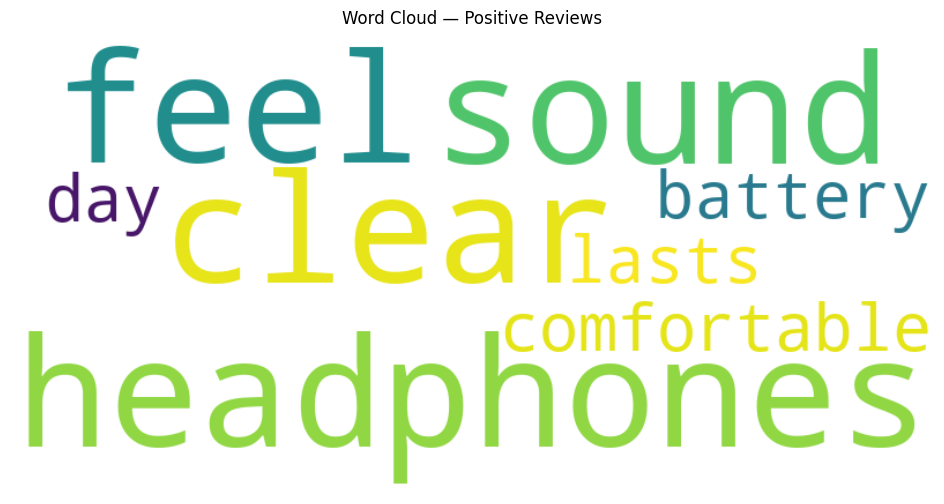

In [6]:
from textblob import TextBlob
import matplotlib.pyplot as plt
from wordcloud import WordCloud

reviews = [
    "The headphones sound clear, feel comfortable, and the battery lasts all day.",
    "The delivery was late and the product stopped working after two days.",
    "The package arrived today. I have used the product once."
]

def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    return "Neutral"

review_results = []
for review in reviews:
    blob = TextBlob(review)
    polarity = blob.sentiment.polarity
    subjectivity = blob.sentiment.subjectivity
    label = classify_sentiment(polarity)
    review_results.append((review, polarity, subjectivity, label))
    print(f"Review: {review}\nPolarity: {polarity:.3f} | "
          f"Subjectivity: {subjectivity:.3f} | Class: {label}\n")

positive_reviews = [r for r, p, s, label in review_results if label == "Positive"]
if positive_reviews:
    wc = WordCloud(width=800, height=400, background_color="white",
                   stopwords=stop_words, collocations=False).generate(" ".join(positive_reviews))
    plt.figure(figsize=(12, 6))
    plt.imshow(wc, interpolation="bilinear")
    plt.axis("off")
    plt.title("Word Cloud — Positive Reviews")
    plt.show()
else:
    print("No positive reviews found, so a word cloud cannot be generated.")


## Q6. Text generation with an LSTM

**Question:** Choose a paragraph of around 100 words as training data. Tokenize it using Keras `Tokenizer`, create input sequences, build and train a simple LSTM or Dense model, and generate 2–3 lines from a seed word.

In [9]:
# TensorFlow/Keras is required for this section. The setup cell installs it.

import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense

training_text = """
Technology is most useful when it solves a real problem for people.
A thoughtful design begins by understanding the needs of its users.
Data can help a system recognize patterns and make better predictions.
However, reliable results depend on good data and careful testing.
People should be able to understand how a system works and where it may fail.
When developers consider privacy, fairness, and accessibility,
technology can become a helpful part of everyday life.
Learning is a continuous process of asking questions, trying ideas,
and improving a solution based on feedback.
"""

tokenizer = Tokenizer()
tokenizer.fit_on_texts([training_text])
total_words = len(tokenizer.word_index) + 1
sequences = tokenizer.texts_to_sequences([training_text])[0]

# Use progressively longer prefixes as training examples.
input_sequences = []
for i in range(1, len(sequences)):
    input_sequences.append(sequences[:i+1])

max_seq_len = max(len(seq) for seq in input_sequences)
input_sequences = pad_sequences(input_sequences, maxlen=max_seq_len, padding="pre")
X, y = input_sequences[:, :-1], input_sequences[:, -1]
y = tf.keras.utils.to_categorical(y, num_classes=total_words)

model = Sequential([
    Embedding(total_words, 32),
    LSTM(64),
    Dense(total_words, activation="softmax")
])
model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
model.summary()

# Small training corpus: keep epochs modest; output is a demonstration, not fluent language.
model.fit(X, y, epochs=100, verbose=0)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)              │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ ?                           │     0 (unbuilt) │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ ?                           │     0 (unbuilt) │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [8]:
def generate_text(seed_text, next_words=20):
    result = seed_text.lower()
    for _ in range(next_words):
        seq = tokenizer.texts_to_sequences([result])[0]
        seq = pad_sequences([seq], maxlen=max_seq_len - 1, padding="pre")
        probabilities = model.predict(seq, verbose=0)[0]
        next_id = int(np.argmax(probabilities))
        next_word = tokenizer.index_word.get(next_id, "")
        if not next_word:
            break
        result += " " + next_word
    return result

print("Generated lines (seed: technology):")
print(generate_text("technology", 12))
print(generate_text("technology", 12))
print(generate_text("technology", 12))


Generated lines (seed: technology):
technology a most a a a real a problem problem for a thoughtful
technology a most a a a real a problem problem for a thoughtful
technology a most a a a real a problem problem for a thoughtful
